# 05 · MFPCA (Happ y Greven, 2018)

**Fase del plan:** F5 – MFPCA.

**Objetivo:** representar cada país como un vector de curvas $\mathbf X_i(t)=(X_i^{(1)}(t),\dots,X_i^{(p)}(t))$ de los indicadores núcleo (TFR, LEx, CNMR_t) e identificar los modos principales de **co-variación temporal conjunta**. Sus scores $\hat\rho_{ir}$ son el insumo del clustering (F6).

**Entradas:** `output/data/curvas_suaves_1950_2023.rds` (F3), `output/data/meta_paises.rds`, `output/data/config.rds`. Se usan los 200 países no pequeños, `IND_NUCLEO` y el horizonte 1950–2023.

**Salidas:**
- `output/data/mfpca_nucleo_1950_2023.rds`: objeto MFPCA, scores con `ISO3_code`, `Location` y región, $L$, $\hat\mu_k$ y $\hat v_k$.
- `output/data/funciones_mfpca.rds`: la función `correr_mfpca()` para F8.
- Tabla `output/tables/mfpca_fve_nucleo_1950_2023.csv|.tex` y figuras `mfpca_*`.


## Configuración


In [1]:
suppressPackageStartupMessages({
  library(fda)          # antes que tidyverse (MASS enmascara select)
  library(funData)
  library(MFPCA)
  library(tidyverse)
  library(GGally)
  library(patchwork)
  library(here)
})
cfg <- readRDS(here::here("output/data/config.rds")); invisible(list2env(cfg, envir = globalenv())); set.seed(SEED)
options(repr.plot.width = 12, repr.plot.height = 7, repr.plot.res = 120, width = 150)
stopifnot(identical(select, dplyr::select))

meta_paises <- readRDS(here::here("output/data/meta_paises.rds"))
meta  <- meta_paises |> filter(!es_pequeno)
IND   <- replace(IND_NUCLEO, IND_NUCLEO == "CNMR", "CNMR_t")
ANIOS <- HORIZONTE[1]:HORIZONTE[2]
p_ind <- length(IND)
X <- readRDS(here::here("output/data/curvas_suaves_1950_2023.rds"))[IND]

stopifnot(all(sapply(X, \(M) identical(dim(M), c(200L, length(ANIOS))) && identical(rownames(M), meta$ISO3_code))))
CAPTION <- "Fuente: UN WPP 2024"
ETIQ <- c(TFR = "TFR (hijos por mujer)", LEx = "LEx (años)", CNMR_t = "asinh(CNMR)")
COL_REG <- setNames(c("#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2"), sort(unique(meta$region)))
cat("Indicadores:", IND, "| países:", nrow(meta), "| años:", range(ANIOS), "| FVE_UMBRAL:", FVE_UMBRAL, "\n")


Indicadores: TFR LEx CNMR_t | países: 200 | años: 1950 2023 | FVE_UMBRAL: 0.9 


## 1. Formulación

**Normalización (Chiou, Chen y Yang, 2014).** Los indicadores tienen escalas y varianzas muy distintas: la varianza entre países de LEx es ~50 veces la de TFR. Para que ninguno domine por su unidad, cada curva se estandariza punto a punto:
$$
Z_i^{(k)}(t)=\frac{X_i^{(k)}(t)-\hat\mu_k(t)}{\sqrt{\hat v_k(t)}},\qquad
\hat\mu_k(t)=\frac1n\sum_{i}X_i^{(k)}(t),\quad
\hat v_k(t)=\frac1{n-1}\sum_{i}\big(X_i^{(k)}(t)-\hat\mu_k(t)\big)^2 .
$$
Así, $\mathbb E\,Z^{(k)}(t)=0$ y $\operatorname{Var}Z^{(k)}(t)=1$ para todo $t$ y todo $k$, de modo que cada indicador aporta la misma varianza total $\int_{\mathcal T}1\,dt=|\mathcal T|$. Esto exige la condición S4, $\min_t\hat v_k(t)>0$, verificada en F3.

**Espacio y covarianza.** $\mathbf Z_i=(Z_i^{(1)},\dots,Z_i^{(p)})$ vive en el espacio producto $\mathcal H=L^2(\mathcal T)^p$, con producto interno
$$
\langle\!\langle \mathbf f,\mathbf g\rangle\!\rangle=\sum_{k=1}^{p}w_k\int_{\mathcal T}f^{(k)}(t)\,g^{(k)}(t)\,dt,\qquad w_k=1 .
$$
El operador de covarianza tiene núcleo matricial $C_{kl}(s,t)=\operatorname{Cov}\big(Z^{(k)}(s),Z^{(l)}(t)\big)$. Sus pares propios $(\nu_r,\boldsymbol\psi_r)$, con $\boldsymbol\psi_r=(\psi_r^{(1)},\dots,\psi_r^{(p)})$ y $\langle\!\langle\boldsymbol\psi_r,\boldsymbol\psi_{r'}\rangle\!\rangle=\delta_{rr'}$, satisfacen $\sum_l\int C_{kl}(s,t)\,\psi_r^{(l)}(s)\,ds=\nu_r\,\psi_r^{(k)}(t)$.

**Expansión de Karhunen–Loève multivariada.**
$$
\mathbf Z_i(t)=\sum_{r=1}^{\infty}\rho_{ir}\,\boldsymbol\psi_r(t),\qquad \rho_{ir}=\langle\!\langle\mathbf Z_i,\boldsymbol\psi_r\rangle\!\rangle,\quad \operatorname{Var}(\rho_{ir})=\nu_r,
$$
que se trunca en $\mathbf Z_i(t)\approx\sum_{r=1}^{L}\hat\rho_{ir}\hat{\boldsymbol\psi}_r(t)$ con
$$
L=\min\Big\{L:\ \mathrm{FVE}(L)=\frac{\sum_{r\le L}\hat\nu_r}{\sum_{k}\int_{\mathcal T}\widehat{\operatorname{Var}}\,Z^{(k)}(t)\,dt}\ \ge\ 0.90\Big\}.
$$
El denominador es la varianza total de los datos, que tras la normalización vale $p\,|\mathcal T|=3\times73=219$. No se usa la suma de los $M$ valores propios calculados, porque eso sobreestimaría el FVE.

**Estimación (Happ y Greven, 2018).** Primero se hace un FPCA univariado de cada $Z^{(k)}$ con $m_k$ componentes y scores $\xi^{(k)}_{im}$. Luego se diagonaliza la covarianza conjunta de todos los scores univariados, $\mathbf Z=[\boldsymbol\xi^{(1)}|\cdots|\boldsymbol\xi^{(p)}]$, de dimensión $n\times\sum_k m_k$. Sus vectores propios dan los coeficientes de $\hat{\boldsymbol\psi}_r$ en las bases univariadas, y $\hat\rho_{ir}$ se obtiene por proyección.


## 2. Normalización de Chiou
Se calculan $\hat\mu_k(t)$ y $\hat v_k(t)$ en la rejilla anual y se verifica que, tras normalizar, la media puntual es ~0 y la varianza puntual ~1 en cada año.


In [2]:
mu_hat <- lapply(X, colMeans)
v_hat  <- lapply(X, \(M) apply(M, 2, var))
stopifnot(all(sapply(v_hat, min) > 1e-6))   # S4
Z <- imap(X, \(M, k) sweep(sweep(M, 2, mu_hat[[k]], "-"), 2, sqrt(v_hat[[k]]), "/"))

chequeo <- imap_dfr(Z, \(M, k) tibble(indicador = k,
                                      max_abs_media = max(abs(colMeans(M))),
                                      max_abs_var_menos_1 = max(abs(apply(M, 2, var) - 1))))
print(as.data.frame(chequeo), row.names = FALSE)
stopifnot(all(chequeo$max_abs_media < 1e-10), all(chequeo$max_abs_var_menos_1 < 1e-10))


 indicador max_abs_media max_abs_var_menos_1
       TFR  2.542966e-15        1.443290e-15
       LEx  6.081802e-15        1.332268e-15
    CNMR_t  1.110223e-16        1.332268e-15


## 3. Objeto `multiFunData`
Cada indicador normalizado se guarda como un `funData` (200 observaciones en la rejilla de años) y los $p=3$ se combinan en un `multiFunData`. La varianza total que sirve de denominador del FVE se calcula integrando, con la regla del trapecio, la varianza puntual de cada elemento.


In [3]:
mfd <- multiFunData(lapply(Z, \(M) funData(argvals = ANIOS, X = unname(M))))
names(mfd) <- IND
trapecio <- function(y, x) sum(diff(x) * (head(y, -1) + tail(y, -1)) / 2)
var_total <- sum(sapply(Z, \(M) trapecio(apply(M, 2, var), ANIOS)))
print(mfd)
cat(sprintf("Varianza total (denominador del FVE): %.2f  [= p × |T| = %d × %d]\n", var_total, p_ind, diff(range(ANIOS))))
stopifnot(nObs(mfd) == 200, length(mfd) == p_ind, abs(var_total - p_ind * diff(range(ANIOS))) < 1e-8)


An object of class "multiFunData"
[[1]]
Functional data with 200 observations of 1-dimensional support
argvals:
	1950 1951 ... 2023		(74 sampling points)
X:
	array of size 200 x 74 

[[2]]
Functional data with 200 observations of 1-dimensional support
argvals:
	1950 1951 ... 2023		(74 sampling points)
X:
	array of size 200 x 74 

[[3]]
Functional data with 200 observations of 1-dimensional support
argvals:
	1950 1951 ... 2023		(74 sampling points)
X:
	array of size 200 x 74 

Varianza total (denominador del FVE): 219.00  [= p × |T| = 3 × 73]


## 4. MFPCA
`MFPCA::MFPCA` con $M=10$ componentes multivariadas, un FPCA univariado (`uFPCA`, PACE) con 6 componentes por indicador, pesos $w_k=1$ y `fit = TRUE`, que devuelve las reconstrucciones $\hat{\mathbf Z}_i$.

**¿Por qué $w_k=1$?** Los pesos del producto interno sirven para compensar diferencias de escala o de varianza entre los elementos. Tras la normalización de Chiou, cada $Z^{(k)}$ tiene varianza 1 en cada $t$ y la misma varianza total $|\mathcal T|$, así que la escala ya está igualada: con pesos unitarios todos los indicadores entran en igualdad de condiciones. Usar además pesos como $w_k=1/\int\hat v_k$ (la propuesta de Happ y Greven para datos sin normalizar) duplicaría la corrección. Con $w_k=1$, cuánto pesa cada indicador en una componente depende solo de su estructura de covarianza, no de su unidad.

**Convención de signo.** Como el signo de $\hat{\boldsymbol\psi}_r$ es arbitrario, se fija para que $\sum_k\int\hat\psi_r^{(k)}(t)\,dt>0$. Los scores cambian de signo junto con las autofunciones.


In [4]:
fijar_signo <- function(m) {
  integ <- Reduce(`+`, lapply(m$functions@.Data, \(f) apply(f@X, 1, trapecio, x = f@argvals[[1]])))
  s <- ifelse(integ < 0, -1, 1)
  m$functions <- multiFunData(lapply(m$functions@.Data, \(f) funData(f@argvals, sweep(f@X, 1, s, `*`))))
  m$scores  <- sweep(m$scores, 2, s, `*`)
  m$vectors <- sweep(m$vectors, 2, s, `*`)
  m
}

set.seed(SEED)
mfpca <- MFPCA(mfd, M = 10, uniExpansions = rep(list(list(type = "uFPCA", npc = 6)), p_ind),
               weights = rep(1, p_ind), fit = TRUE)
mfpca <- fijar_signo(mfpca)
names(mfpca$functions) <- IND
colnames(mfpca$scores) <- paste0("rho", 1:10)

# Verificaciones: ortonormalidad en el espacio producto y varianza de scores = valores propios
G <- outer(1:10, 1:10, Vectorize(\(a, b) sum(sapply(1:p_ind, \(k)
       trapecio(mfpca$functions[[k]]@X[a, ] * mfpca$functions[[k]]@X[b, ], ANIOS)))))
cat(sprintf("Ortonormalidad: max |G - I| = %.2e\n", max(abs(G - diag(10)))))
cat(sprintf("max |var(scores) - nu| / nu = %.2e\n", max(abs(apply(mfpca$scores, 2, var) - mfpca$values) / mfpca$values)))
cat(sprintf("max |media de los scores| = %.2e | max |media MFPCA| = %.2e\n",
            max(abs(colMeans(mfpca$scores))), max(sapply(mfpca$meanFunction@.Data, \(f) max(abs(f@X))))))
stopifnot(max(abs(G - diag(10))) < 1e-2)


Ortonormalidad: max |G - I| = 6.14e-15
max |var(scores) - nu| / nu = 8.58e-16
max |media de los scores| = 7.44e-16 | max |media MFPCA| = 9.32e-16


## 5. Selección de $L$ y FVE
$L$ es el menor número de componentes con FVE acumulado ≥ `FVE_UMBRAL` (0.90), con la varianza total (219) como denominador. También se informa qué fracción de esa varianza capturan las $M=10$ componentes calculadas.


 componente valor_propio FVE (%) FVE acum (%)
       rho1      120.088   54.83        54.83
       rho2       32.045   14.63        69.47
       rho3       14.123    6.45        75.92
       rho4       12.420    5.67        81.59
       rho5        5.480    2.50        84.09
       rho6        5.077    2.32        86.41
       rho7        3.940    1.80        88.21
       rho8        3.223    1.47        89.68
       rho9        2.691    1.23        90.91
      rho10        2.008    0.92        91.82

L = 9 (FVE acumulado = 90.9 %) | las 10 componentes explican 91.8 %


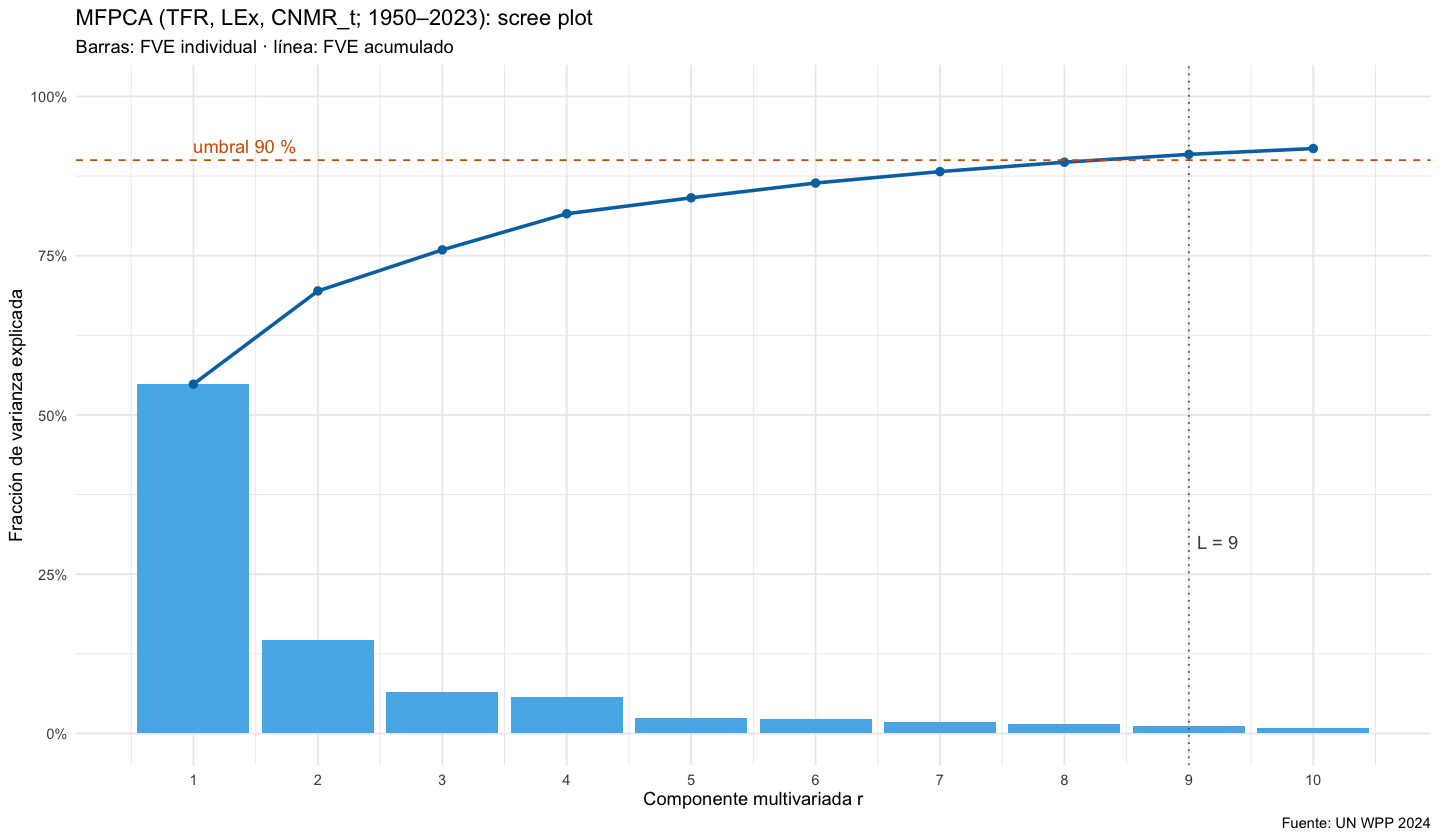

In [5]:
nu  <- mfpca$values
fve <- nu / var_total
tabla_fve <- tibble(componente = paste0("rho", 1:10), valor_propio = nu, FVE = fve, FVE_acum = cumsum(fve))
L <- which(tabla_fve$FVE_acum >= FVE_UMBRAL)[1]
if (is.na(L)) stop("Las M = 10 componentes no alcanzan FVE_UMBRAL: aumentar M.")
guardar_tabla(tabla_fve |> mutate(across(-componente, ~ round(.x, 5))), "mfpca_fve_nucleo_1950_2023", tex = TRUE)
tabla_fve |> mutate(valor_propio = round(valor_propio, 3), across(c(FVE, FVE_acum), ~ round(100 * .x, 2))) |>
  rename(`FVE (%)` = FVE, `FVE acum (%)` = FVE_acum) |> as.data.frame() |> print(row.names = FALSE)
cat(sprintf("\nL = %d (FVE acumulado = %.1f %%) | las 10 componentes explican %.1f %%\n",
            L, 100 * tabla_fve$FVE_acum[L], 100 * sum(fve)))

p <- ggplot(tabla_fve, aes(1:10)) +
  geom_col(aes(y = FVE), fill = "#56B4E9") +
  geom_line(aes(y = FVE_acum), colour = "#0072B2", linewidth = 1) +
  geom_point(aes(y = FVE_acum), colour = "#0072B2", size = 2) +
  geom_hline(yintercept = FVE_UMBRAL, linetype = "dashed", colour = "#D55E00") +
  geom_vline(xintercept = L, linetype = "dotted", colour = "grey40") +
  annotate("text", x = L, y = 0.3, label = paste0("L = ", L), hjust = -0.2, colour = "grey30") +
  annotate("text", x = 1, y = FVE_UMBRAL, label = paste0("umbral ", 100 * FVE_UMBRAL, " %"),
           vjust = -0.6, hjust = 0, colour = "#D55E00") +
  scale_x_continuous(breaks = 1:10) + scale_y_continuous(labels = scales::percent, limits = c(0, 1)) +
  labs(title = "MFPCA (TFR, LEx, CNMR_t; 1950–2023): scree plot",
       subtitle = "Barras: FVE individual · línea: FVE acumulado",
       x = "Componente multivariada r", y = "Fracción de varianza explicada", caption = CAPTION) +
  theme_minimal(base_size = 11)
guardar_fig(p, "mfpca_scree", w = 9, h = 5.5); p


## 6. Cuasi-degeneración de los valores propios
Si dos valores propios consecutivos son casi iguales ($\hat\nu_{r+1}/\hat\nu_r>0.9$), las autofunciones correspondientes están mal identificadas: cualquier rotación dentro del subespacio que generan es casi igual de válida, y pequeñas perturbaciones de los datos pueden mezclarlas. En ese caso se interpreta el **subespacio**, no cada autofunción por separado. Para el clustering no hay problema, porque las distancias euclídeas entre los vectores de scores son invariantes a rotaciones dentro del subespacio retenido.


In [6]:
cuasi <- tibble(r = 1:L, nu_r = nu[1:L], nu_r1 = nu[2:(L + 1)], razon = nu_r1 / nu_r, cuasi_degenerado = razon > 0.9)
cuasi |> mutate(across(c(nu_r, nu_r1), ~ round(.x, 3)), razon = round(razon, 3)) |> as.data.frame() |> print(row.names = FALSE)
pares <- cuasi |> filter(cuasi_degenerado)
if (nrow(pares) > 0) {
  cat("\n*** ATENCIÓN: cuasi-degeneración en los pares", paste0("(", pares$r, ",", pares$r + 1, ")", collapse = ", "), "***\n")
} else cat("\nNo hay pares cuasi-degenerados (todas las razones <= 0.9).\n")


 r    nu_r  nu_r1 razon cuasi_degenerado
 1 120.088 32.045 0.267            FALSE
 2  32.045 14.123 0.441            FALSE
 3  14.123 12.420 0.879            FALSE
 4  12.420  5.480 0.441            FALSE
 5   5.480  5.077 0.926             TRUE
 6   5.077  3.940 0.776            FALSE
 7   3.940  3.223 0.818            FALSE
 8   3.223  2.691 0.835            FALSE
 9   2.691  2.008 0.746            FALSE

*** ATENCIÓN: cuasi-degeneración en los pares (5,6) ***


**Resultado del diagnóstico de cuasi-degeneración:**
- ⚠️ **Par (5, 6): $\hat\nu_6/\hat\nu_5=0.926>0.9$. Cuasi-degenerado.** $\rho_5$ (sobre todo TFR y LEx) y $\rho_6$ (casi solo CNMR_t) explican 2.5 % y 2.3 %. Sus autofunciones pueden rotar entre sí ante pequeños cambios de los datos, así que se interpreta el **plano** $\{\hat{\boldsymbol\psi}_5,\hat{\boldsymbol\psi}_6\}$ y no cada componente por separado.
- **Par (3, 4): $0.879$**, justo por debajo del umbral. $\rho_3$ y $\rho_4$ son estables en este ajuste, pero su identificación es frágil y conviene revisarla en la sensibilidad (F8).
- El resto de las razones están entre 0.27 y 0.84.
- Para el clustering (F6), la cuasi-degeneración no afecta las distancias euclídeas entre los vectores $(\hat\rho_{i1},\dots,\hat\rho_{iL})$, que son invariantes a rotaciones dentro del subespacio retenido.


## 7a. Autofunciones multivariadas $\hat\psi_r^{(k)}(t)$
Cada fila es una componente $r=1,\dots,L$ y cada columna un indicador. Los tres paneles de una fila forman **una sola** autofunción multivariada: muestran cómo se mueven juntos los tres indicadores (en escala normalizada) cuando un país tiene un score positivo en esa componente. Una curva cerca de 0 indica que ese indicador casi no participa en la componente. La "participación" de cada indicador, $\|\hat\psi_r^{(k)}\|^2$ (que suma 1 entre los indicadores), aparece en el título de cada panel.


 comp   TFR   LEx CNMR_t
    1 0.471 0.501  0.028
    2 0.022 0.018  0.960
    3 0.623 0.299  0.078
    4 0.058 0.045  0.897
    5 0.481 0.448  0.072
    6 0.011 0.008  0.981
    7 0.075 0.026  0.899
    8 0.254 0.658  0.088
    9 0.055 0.064  0.881


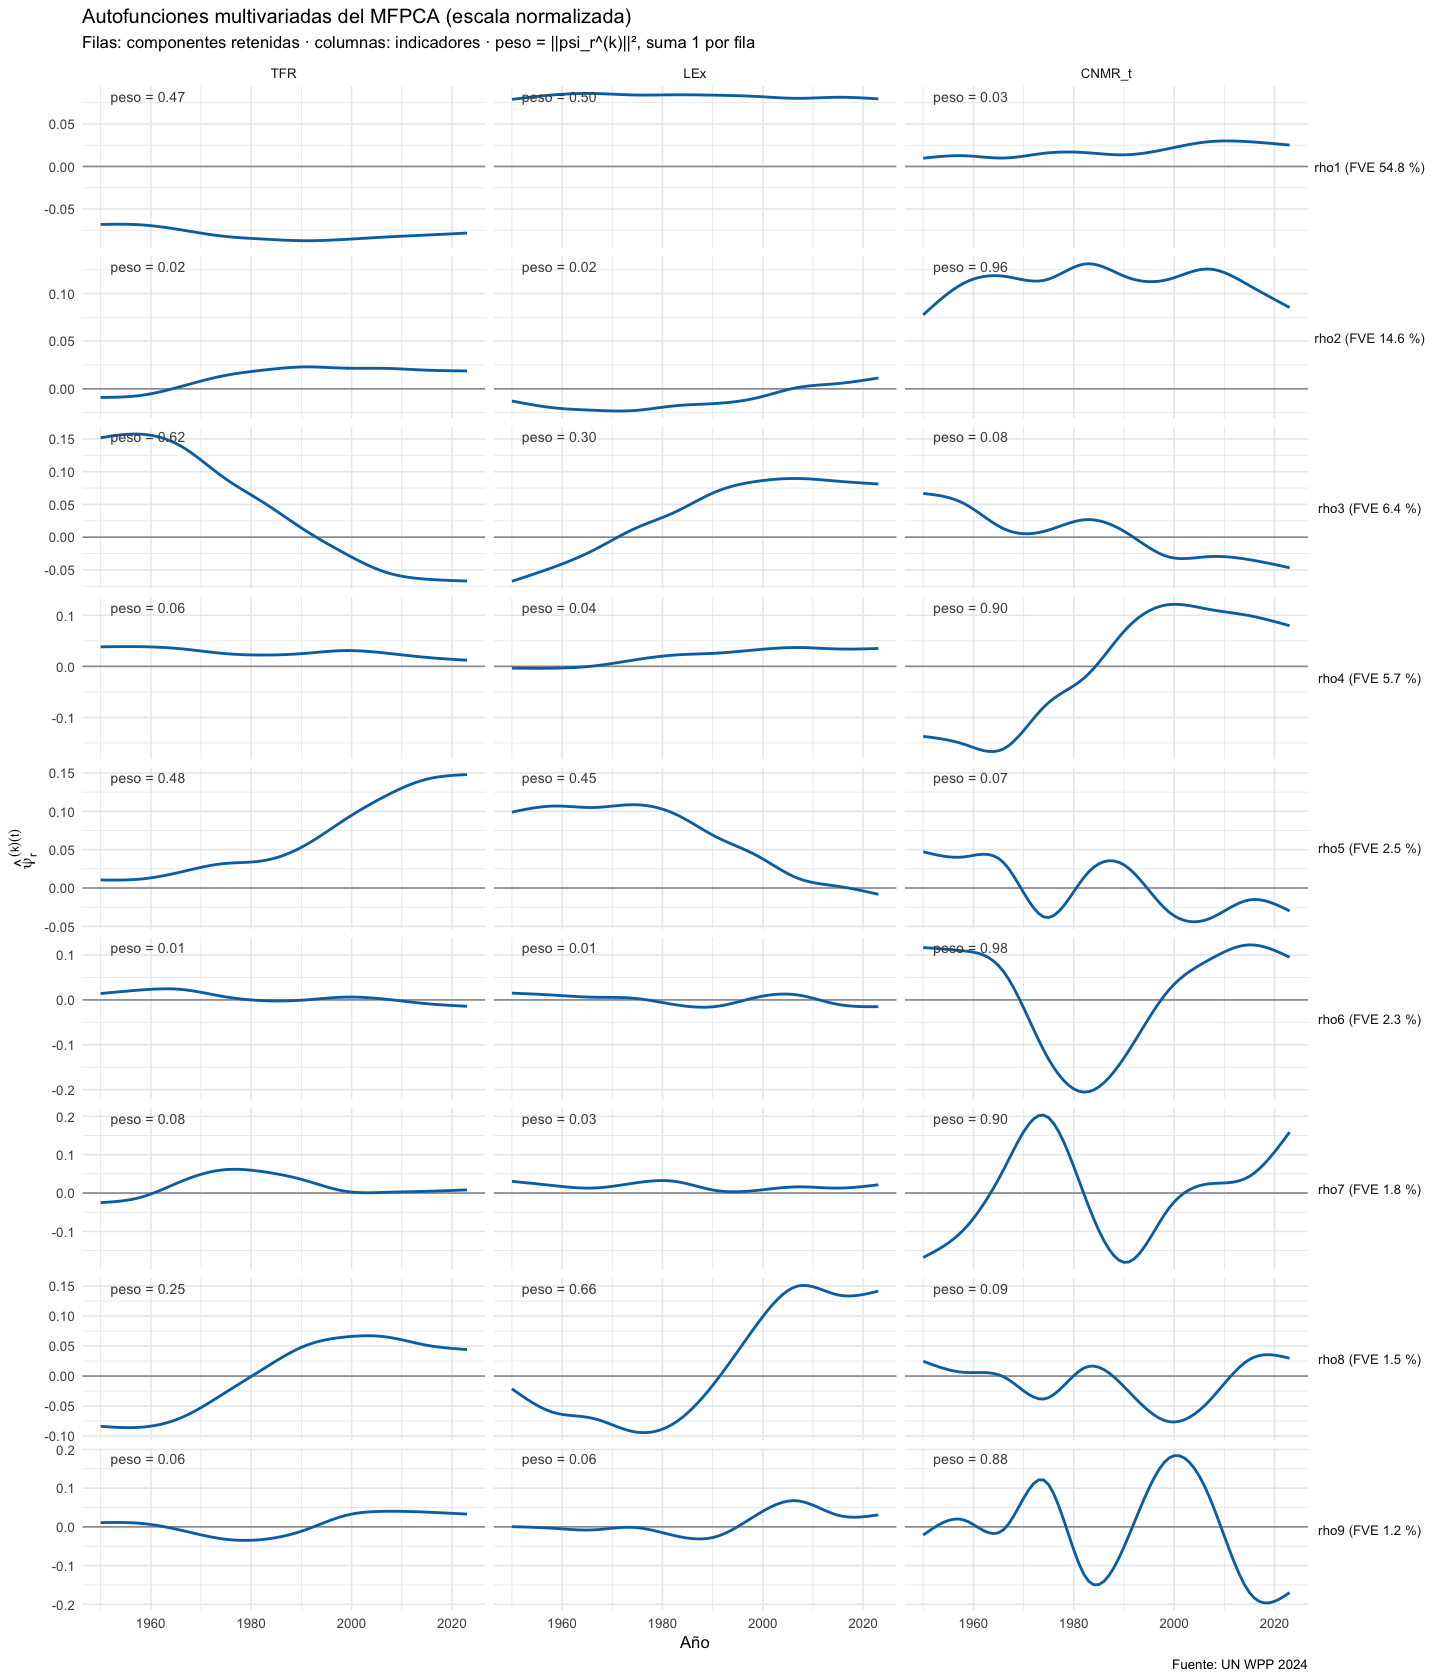

In [7]:
etiq_comp <- sprintf("rho%d (FVE %.1f %%)", 1:L, 100 * fve[1:L])
psi_long <- map_dfr(IND, function(k) {
  Fk <- mfpca$functions[[k]]@X[1:L, , drop = FALSE]
  tibble(indicador = k, comp = rep(1:L, times = length(ANIOS)), Time = rep(ANIOS, each = L), psi = as.vector(Fk))
}) |> mutate(indicador = factor(indicador, levels = IND))
peso <- psi_long |> group_by(comp, indicador) |>
  summarise(peso = trapecio(psi^2, Time), .groups = "drop")
stopifnot(all(abs(tapply(peso$peso, peso$comp, sum) - 1) < 1e-8))
psi_long <- psi_long |> left_join(peso, by = c("comp", "indicador")) |>
  mutate(panel_comp = factor(etiq_comp[comp], levels = etiq_comp),
         panel_ind  = indicador)
peso |> mutate(peso = round(peso, 3)) |> pivot_wider(names_from = indicador, values_from = peso) |>
  as.data.frame() |> print(row.names = FALSE)

p <- ggplot(psi_long, aes(Time, psi)) +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_line(colour = "#0072B2", linewidth = 0.8) +
  geom_text(data = distinct(psi_long, panel_comp, panel_ind, peso),
            aes(x = 1952, y = Inf, label = sprintf("peso = %.2f", peso)), hjust = 0, vjust = 1.5, size = 3, colour = "grey30") +
  facet_grid(panel_comp ~ panel_ind, scales = "free_y") +
  labs(title = "Autofunciones multivariadas del MFPCA (escala normalizada)",
       subtitle = "Filas: componentes retenidas · columnas: indicadores · peso = ||psi_r^(k)||², suma 1 por fila",
       x = "Año", y = expression(hat(psi)[r]^(k)(t)), caption = CAPTION) +
  theme_minimal(base_size = 10) + theme(strip.text.y = element_text(angle = 0))
options(repr.plot.height = 14)
guardar_fig(p, "mfpca_autofunciones", w = 11, h = 15); p
options(repr.plot.height = 7)


## 7b. Perturbaciones en la escala original (figura interpretativa principal)
Para cada componente $r$ e indicador $k$ se dibuja, en las unidades originales,
$$
X^{(k)}_{\pm}(t)=\hat\mu_k(t)+\sqrt{\hat v_k(t)}\,\Big(\pm2\sqrt{\hat\nu_r}\,\hat\psi_r^{(k)}(t)\Big),
$$
es decir, la trayectoria conjunta de un país con score $\pm2$ desviaciones estándar en la componente $r$ y 0 en las demás. La línea negra es la media $\hat\mu_k(t)$.


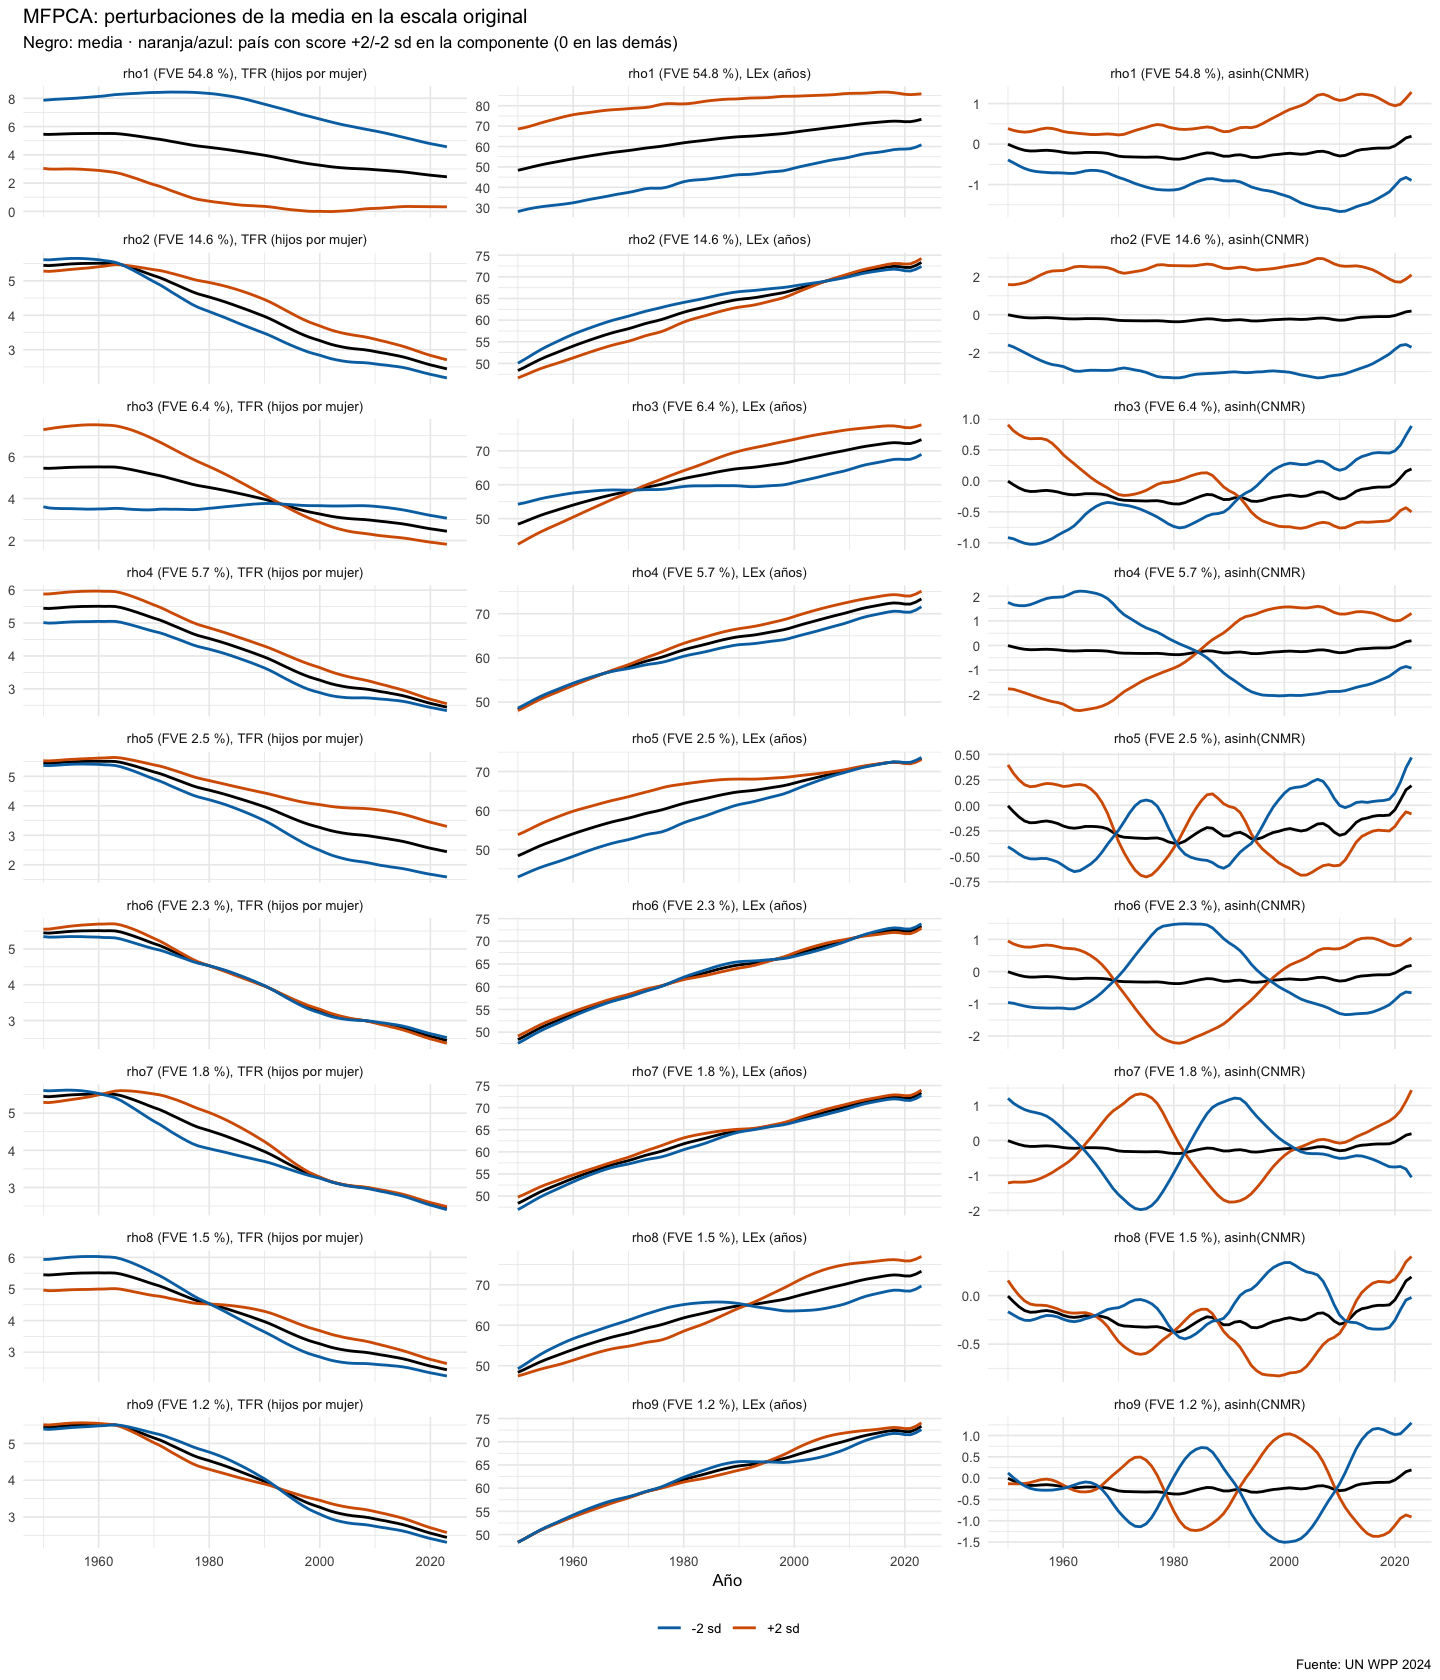

In [8]:
pert <- map_dfr(1:L, function(r) map_dfr(IND, function(k) {
  d <- 2 * sqrt(nu[r]) * sqrt(v_hat[[k]]) * mfpca$functions[[k]]@X[r, ]
  tibble(comp = r, indicador = k, Time = ANIOS, media = mu_hat[[k]], mas = mu_hat[[k]] + d, menos = mu_hat[[k]] - d)
})) |> mutate(indicador = factor(indicador, levels = IND, labels = ETIQ[IND]),
              panel_comp = factor(etiq_comp[comp], levels = etiq_comp))

p <- ggplot(pert, aes(Time)) +
  geom_line(aes(y = media), colour = "black", linewidth = 0.8) +
  geom_line(aes(y = mas, colour = "+2 sd"), linewidth = 0.8) +
  geom_line(aes(y = menos, colour = "-2 sd"), linewidth = 0.8) +
  facet_wrap(~ panel_comp + indicador, ncol = 3, scales = "free_y",
             labeller = labeller(.multi_line = FALSE)) +
  scale_colour_manual(values = c("+2 sd" = "#D55E00", "-2 sd" = "#0072B2"), name = NULL) +
  labs(title = "MFPCA: perturbaciones de la media en la escala original",
       subtitle = "Negro: media · naranja/azul: país con score +2/-2 sd en la componente (0 en las demás)",
       x = "Año", y = NULL, caption = CAPTION) +
  theme_minimal(base_size = 10) + theme(legend.position = "bottom", strip.text = element_text(size = 8))
options(repr.plot.height = 14)
guardar_fig(p, "mfpca_perturbaciones", w = 11, h = 15); p
options(repr.plot.height = 7)


## 7c. Matriz de dispersión de los scores retenidos
Diagonal: densidad de cada score por región. Triángulo inferior: dispersión de los países, coloreados por región. El triángulo superior se deja en blanco porque las correlaciones entre scores son 0 por construcción. Si aparecen nubes separadas, hay estructura de grupos que el clustering (F6) puede aprovechar.


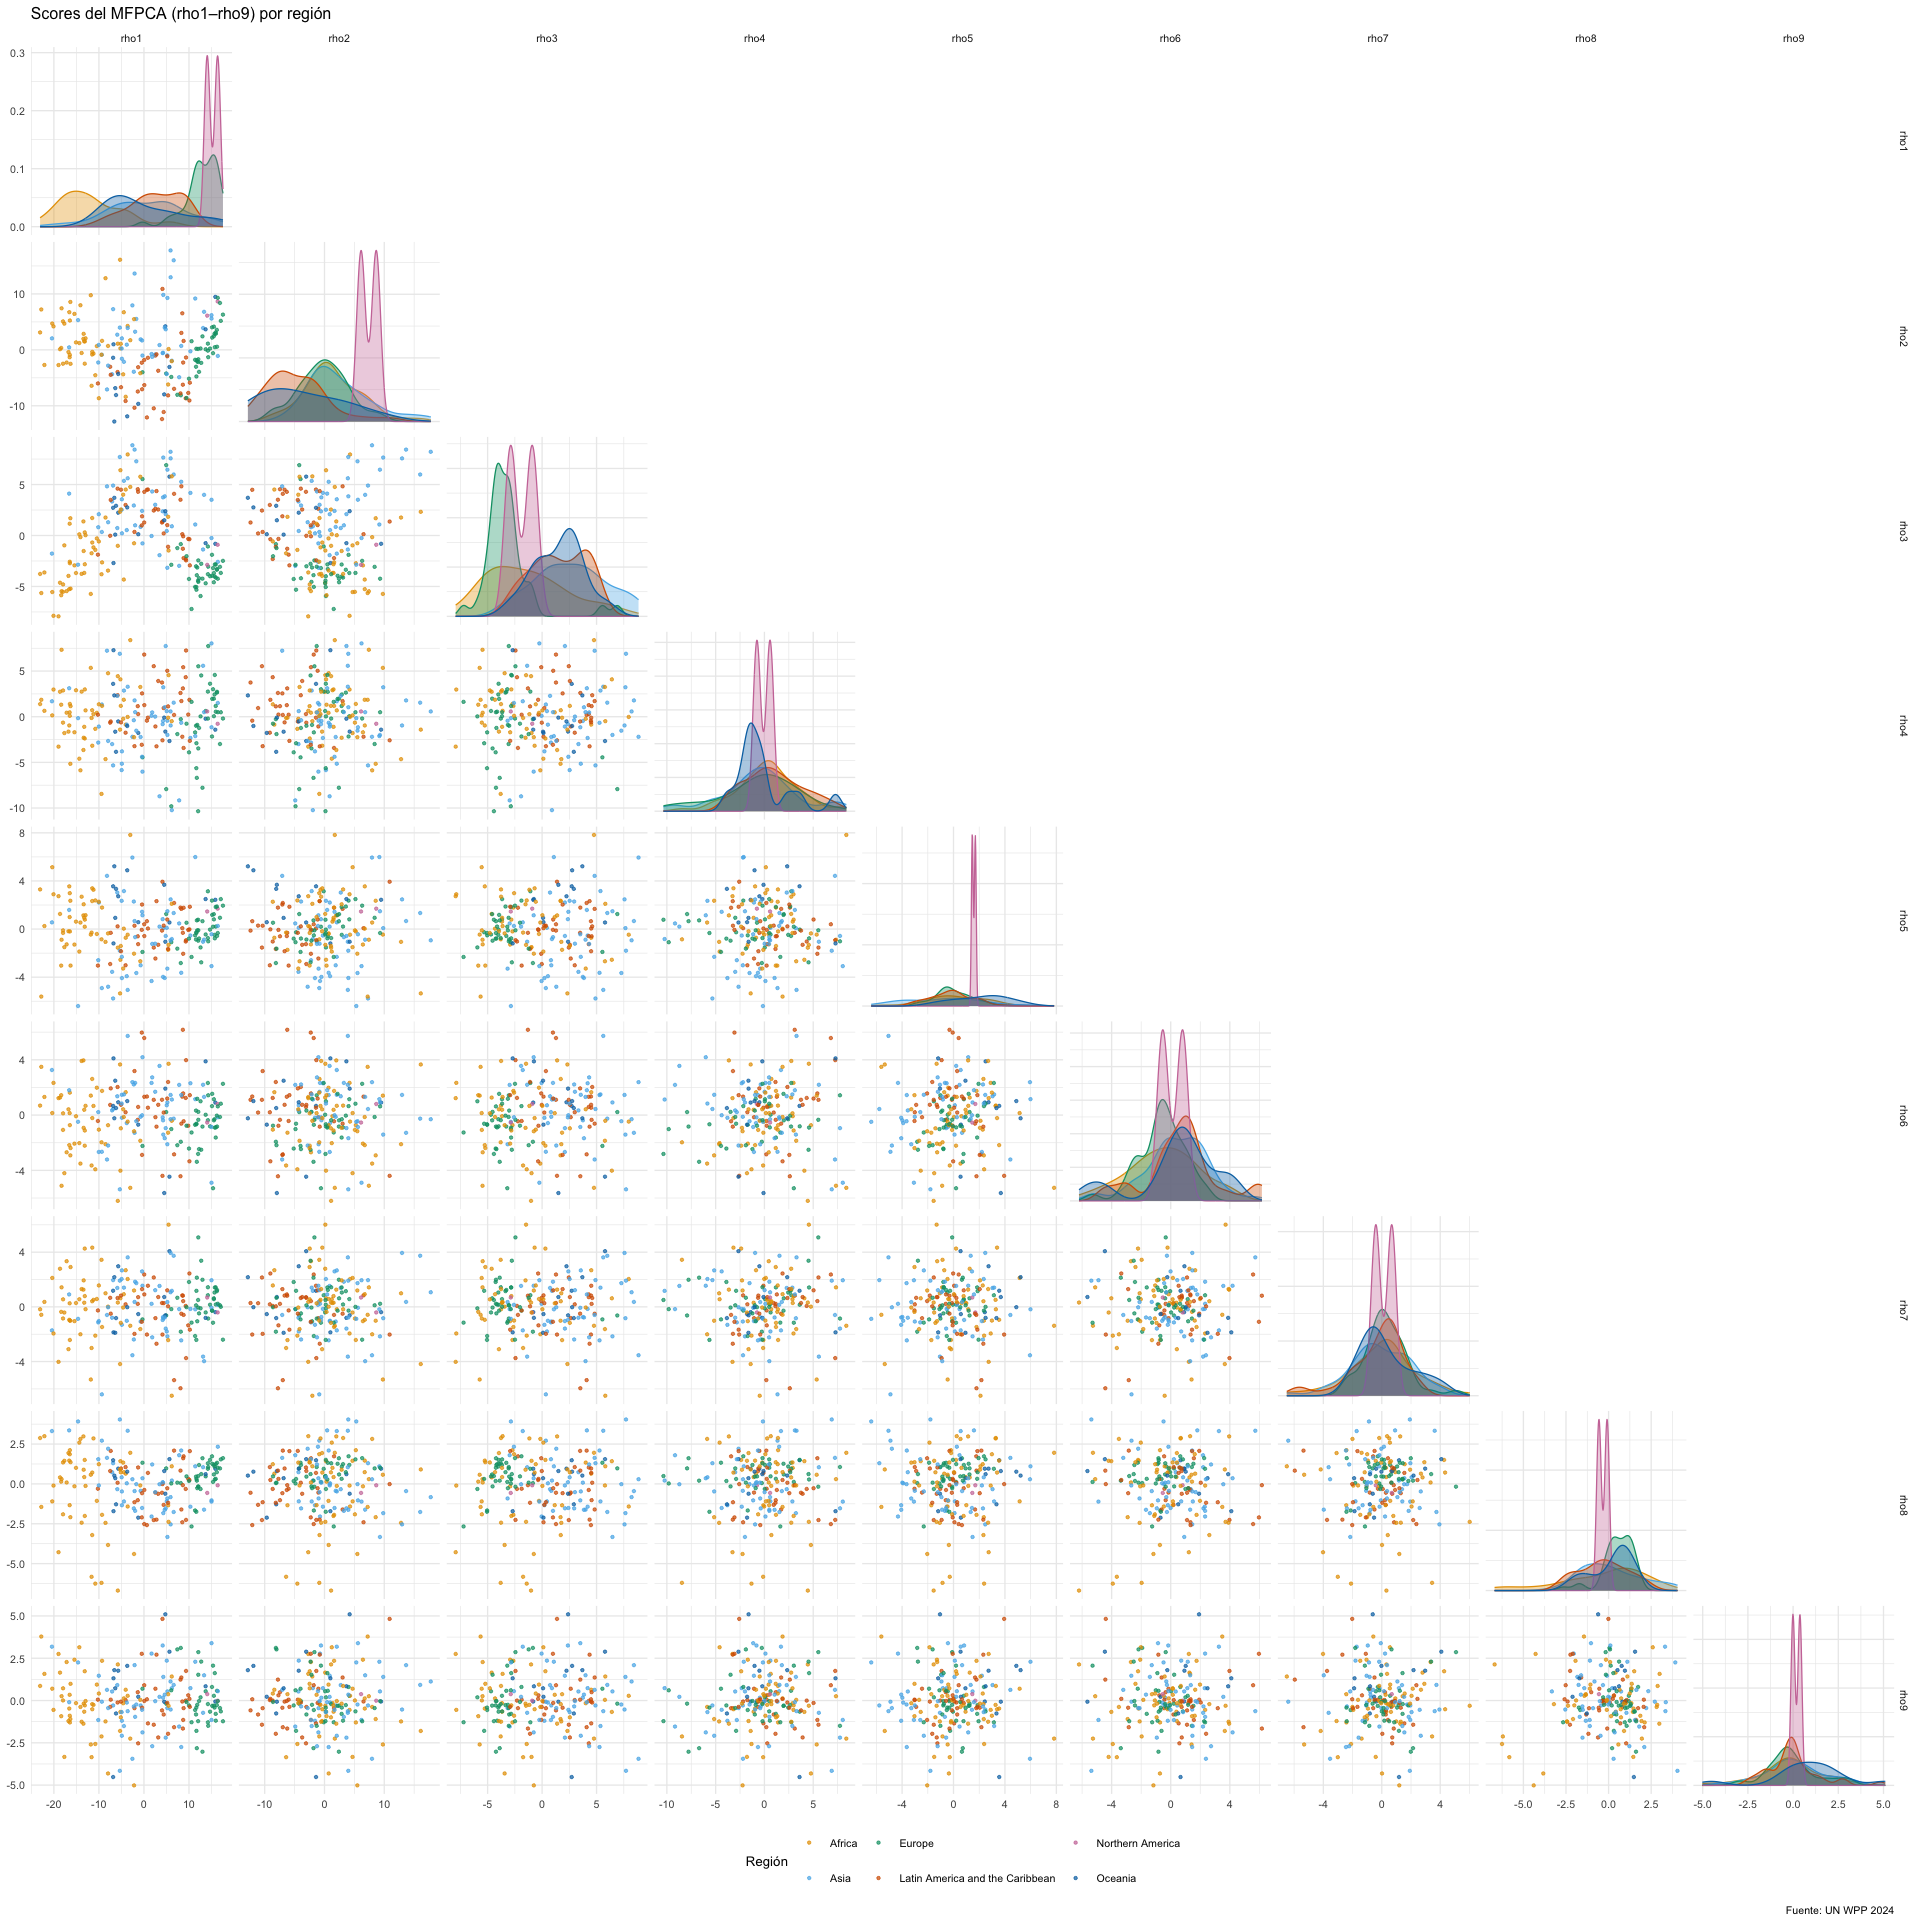

In [9]:
scores <- as_tibble(mfpca$scores[, 1:10], .name_repair = "minimal") |>
  mutate(ISO3_code = meta$ISO3_code, Location = meta$Location, region = factor(meta$region, levels = names(COL_REG)), .before = 1)
stopifnot(max(abs(cor(mfpca$scores[, 1:L])[upper.tri(diag(L))])) < 1e-8)   # scores incorrelados

# Paleta por región como opción por defecto, para que llegue a todos los paneles de ggpairs
op <- options(ggplot2.discrete.colour = unname(COL_REG), ggplot2.discrete.fill = unname(COL_REG))
p <- ggpairs(scores, columns = paste0("rho", 1:L), mapping = aes(colour = region, fill = region),
             upper = "blank",
             lower = list(continuous = wrap("points", size = 0.7, alpha = 0.7)),
             diag  = list(continuous = wrap("densityDiag", alpha = 0.35)),
             legend = c(2, 1), progress = FALSE) +
  labs(title = paste0("Scores del MFPCA (rho1–rho", L, ") por región"), caption = CAPTION, colour = "Región") +
  theme_minimal(base_size = 8) + theme(legend.position = "bottom") + guides(fill = "none")
options(repr.plot.width = 16, repr.plot.height = 16)
guardar_fig(p, "mfpca_ggpairs_scores", w = 16, h = 16); print(p)
options(repr.plot.width = 12, repr.plot.height = 7); options(op)
scores <- scores |> mutate(region = as.character(region))


## 7d. Reconstrucción de Karhunen–Loève de cuatro países extremos
Se eligen los países con el score mínimo y máximo en $\rho_1$ y en $\rho_2$. Para cada uno se compara la curva observada (suavizada en F3) con la reconstrucción truncada en $L$ componentes, devuelta a la escala original:
$$
\hat X_i^{(k)}(t)=\hat\mu_k(t)+\sqrt{\hat v_k(t)}\sum_{r=1}^{L}\hat\rho_{ir}\hat\psi_r^{(k)}(t).
$$


# A tibble: 4 × 5
  ISO3_code Location             region    rho1   rho2
  <chr>     <chr>                <chr>    <dbl>  <dbl>
1 NER       Niger                Africa  -23.1    3.11
2 CHE       Switzerland          Europe   17.5    6.30
3 WSM       Samoa                Oceania  -6.58 -12.8 
4 ARE       United Arab Emirates Asia      5.90  17.8 


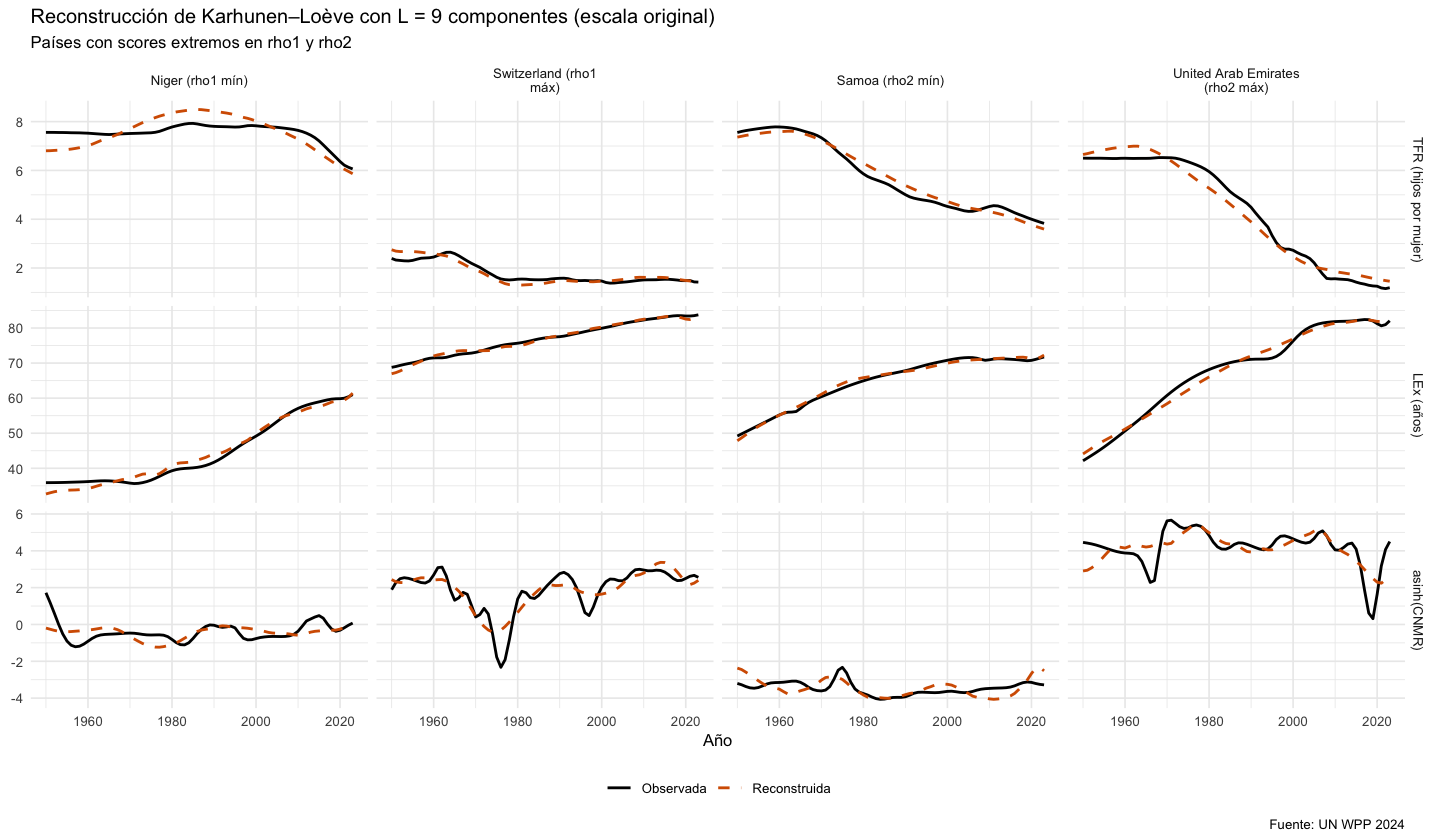

In [10]:
reconstruir_Z <- function(rows, Lr) {
  lapply(setNames(IND, IND), \(k) mfpca$scores[rows, 1:Lr, drop = FALSE] %*% mfpca$functions[[k]]@X[1:Lr, , drop = FALSE])
}
sel <- unique(c(which.min(scores$rho1), which.max(scores$rho1), which.min(scores$rho2), which.max(scores$rho2)))
etiq_sel <- sprintf("%s (%s)", scores$Location[sel], c("rho1 mín", "rho1 máx", "rho2 mín", "rho2 máx")[seq_along(sel)])
print(scores[sel, c("ISO3_code", "Location", "region", "rho1", "rho2")])

Zhat <- reconstruir_Z(sel, L)
d_rec <- map_dfr(IND, function(k) {
  obs <- X[[k]][sel, , drop = FALSE]
  rec <- sweep(sweep(Zhat[[k]], 2, sqrt(v_hat[[k]]), "*"), 2, mu_hat[[k]], "+")
  tibble(indicador = k, pais = rep(etiq_sel, times = length(ANIOS)), Time = rep(ANIOS, each = length(sel)),
         Observada = as.vector(obs), Reconstruida = as.vector(rec))
}) |> pivot_longer(c(Observada, Reconstruida), names_to = "serie") |>
  mutate(indicador = factor(indicador, levels = IND, labels = ETIQ[IND]), pais = factor(pais, levels = etiq_sel))

p <- ggplot(d_rec, aes(Time, value, colour = serie, linetype = serie)) +
  geom_line(linewidth = 0.8) +
  facet_grid(indicador ~ pais, scales = "free_y", labeller = label_wrap_gen(22)) +
  scale_colour_manual(values = c(Observada = "black", Reconstruida = "#D55E00"), name = NULL) +
  scale_linetype_manual(values = c(Observada = "solid", Reconstruida = "dashed"), name = NULL) +
  labs(title = paste0("Reconstrucción de Karhunen–Loève con L = ", L, " componentes (escala original)"),
       subtitle = "Países con scores extremos en rho1 y rho2", x = "Año", y = NULL, caption = CAPTION) +
  theme_minimal(base_size = 10) + theme(legend.position = "bottom")
guardar_fig(p, "mfpca_reconstruccion", w = 12, h = 8); p


## 8. Error relativo de reconstrucción (MRSE)
$$
\mathrm{MRSE}=\operatorname{mediana}_i\ \frac{\|\mathbf Z_i-\hat{\mathbf Z}_i\|^2}{\|\mathbf Z_i\|^2},\qquad \|\mathbf f\|^2=\sum_{k=1}^{p}\int_{\mathcal T}f^{(k)}(t)^2\,dt ,
$$
calculado en dos versiones: con la reconstrucción truncada en $L$ componentes (la representación que se usa en el clustering) y con el ajuste `fit` de `MFPCA` ($M=10$).


In [11]:
norma2 <- function(lst) Reduce(`+`, lapply(lst, \(M) apply(M^2, 1, trapecio, x = ANIOS)))
Zl <- lapply(IND, \(k) unname(Z[[k]])); names(Zl) <- IND
ZL   <- reconstruir_Z(1:200, L)
Zfit <- lapply(setNames(IND, IND), \(k) mfpca$fit[[which(IND == k)]]@X)
err_L   <- norma2(map2(Zl, ZL,   `-`)) / norma2(Zl)
err_fit <- norma2(map2(Zl, Zfit, `-`)) / norma2(Zl)
stopifnot(max(norma2(map2(Zfit, reconstruir_Z(1:200, 10), `-`))) < 1e-8)  # fit = KL con M = 10
stopifnot(all(err_L >= 0), all(err_fit >= 0))
MRSE_L <- median(err_L); MRSE_fit <- median(err_fit)
cat(sprintf("MRSE (L = %d): %.4f | MRSE (fit, M = 10): %.4f\n", L, MRSE_L, MRSE_fit))
print(round(quantile(err_L, c(0, 0.25, 0.5, 0.75, 0.9, 1)), 4))
cat("Países con mayor error relativo (L):\n")
tibble(ISO3_code = meta$ISO3_code, Location = meta$Location, err = round(err_L, 3)) |> arrange(desc(err)) |> head(6) |> print()


MRSE (L = 9): 0.0719 | MRSE (fit, M = 10): 0.0650
    0%    25%    50%    75%    90%   100% 
0.0064 0.0424 0.0719 0.1334 0.2158 0.5555 
Países con mayor error relativo (L):
# A tibble: 6 × 3
  ISO3_code Location                          err
  <chr>     <chr>                           <dbl>
1 LBN       Lebanon                         0.555
2 SYR       Syrian Arab Republic            0.427
3 PRK       Dem. People's Republic of Korea 0.393
4 NCL       New Caledonia                   0.361
5 LBY       Libya                           0.359
6 VNM       Viet Nam                        0.357


## 9. Guardado


In [12]:
res_principal <- list(mfpca = mfpca, scores = scores, L = L, mu_hat = mu_hat, v_hat = v_hat,
                      tabla_fve = tabla_fve, var_total = var_total, cuasi = cuasi,
                      MRSE = c(L = MRSE_L, fit = MRSE_fit),
                      config = list(indicadores = IND, horizonte = HORIZONTE, excluir_pequenos = TRUE,
                                    normalizar = TRUE, fve_umbral = FVE_UMBRAL))
saveRDS(res_principal, here::here("output/data/mfpca_nucleo_1950_2023.rds"))
chk <- readRDS(here::here("output/data/mfpca_nucleo_1950_2023.rds"))
stopifnot(identical(chk$scores, scores), chk$L == L)
cat("Guardado mfpca_nucleo_1950_2023.rds con elementos:", names(chk), "\n")


Guardado mfpca_nucleo_1950_2023.rds con elementos: mfpca scores L mu_hat v_hat tabla_fve var_total cuasi MRSE config 


# Función reutilizable

`correr_mfpca()` encapsula los pasos 2–9 (normalización, `multiFunData`, MFPCA, convención de signo, selección de $L$, cuasi-degeneración, scores y MRSE) para poder rehacer el análisis en la sensibilidad (F8) cambiando una cosa a la vez.

- `indicadores`: nombres de `IND_*` (se acepta `"CNMR"` y se traduce a `"CNMR_t"`).
- `horizonte`: `c(1950, 2023)` o `c(1950, 2100)`; lee `curvas_suaves_<horizonte>.rds`.
- `excluir_pequenos`: si es `FALSE`, suaviza los 237 países desde `matrices_<horizonte>.rds` con el mismo $\lambda$ por indicador que se eligió en F3 (`fd_<horizonte>.rds`), porque en F3 solo se suavizaron los 200 no pequeños.
- `normalizar`: `TRUE` para la normalización de Chiou; `FALSE` para solo centrar ($Z=X-\hat\mu$).
- `fve_umbral`: umbral para $L$.

La función no depende de objetos globales: todas las llamadas usan `paquete::` y los helpers se definen dentro. Así funciona al cargarla con `readRDS()` en otro notebook. Devuelve una lista con la misma estructura que `mfpca_nucleo_1950_2023.rds`.


In [13]:
correr_mfpca <- function(indicadores, horizonte, excluir_pequenos = TRUE, normalizar = TRUE,
                         fve_umbral = 0.90, M = 10, npc = 6, seed = 20261014) {
  `%>%` <- magrittr::`%>%`
  trapecio <- function(y, x) sum(diff(x) * (utils::head(y, -1) + utils::tail(y, -1)) / 2)
  ind  <- replace(indicadores, indicadores == "CNMR", "CNMR_t")
  anios <- horizonte[1]:horizonte[2]
  suf  <- paste0(horizonte[1], "_", horizonte[2])
  meta_all <- readRDS(here::here("output/data/meta_paises.rds"))

  # --- Curvas suavizadas ---
  if (excluir_pequenos) {
    meta <- meta_all[!meta_all$es_pequeno, ]
    X <- readRDS(here::here("output/data", paste0("curvas_suaves_", suf, ".rds")))[ind]
  } else {
    meta <- meta_all
    crudas <- readRDS(here::here("output/data", paste0("matrices_", suf, ".rds")))[ind]
    lambdas <- readRDS(here::here("output/data", paste0("fd_", suf, ".rds")))
    base <- fda::create.bspline.basis(range(anios), norder = 4, breaks = anios)
    X <- lapply(stats::setNames(ind, ind), function(k) {
      Mk <- crudas[[k]][meta$ISO3_code, as.character(anios)]
      s  <- fda::smooth.basis(anios, t(Mk), fda::fdPar(base, Lfdobj = 2, lambda = lambdas[[k]]$lambda))
      S  <- t(fda::eval.fd(anios, s$fd)); dimnames(S) <- dimnames(Mk); S
    })
  }
  stopifnot(all(sapply(X, function(M) identical(rownames(M), meta$ISO3_code) && ncol(M) == length(anios))))

  # --- Paso 2: normalización (o solo centrado) ---
  mu_hat <- lapply(X, colMeans)
  v_hat  <- lapply(X, function(M) apply(M, 2, stats::var))
  if (normalizar) stopifnot(all(sapply(v_hat, min) > 1e-6))
  Z <- lapply(stats::setNames(ind, ind), function(k) {
    Zk <- sweep(X[[k]], 2, mu_hat[[k]], "-")
    if (normalizar) Zk <- sweep(Zk, 2, sqrt(v_hat[[k]]), "/")
    Zk
  })
  var_total <- sum(sapply(Z, function(M) trapecio(apply(M, 2, stats::var), anios)))

  # --- Pasos 3-4: multiFunData y MFPCA ---
  mfd <- funData::multiFunData(lapply(Z, function(M) funData::funData(argvals = anios, X = unname(M))))
  set.seed(seed)
  m <- MFPCA::MFPCA(mfd, M = M, uniExpansions = rep(list(list(type = "uFPCA", npc = npc)), length(ind)),
                    weights = rep(1, length(ind)), fit = TRUE)
  integ <- Reduce(`+`, lapply(m$functions@.Data, function(f) apply(f@X, 1, trapecio, x = anios)))
  sg <- ifelse(integ < 0, -1, 1)
  m$functions <- funData::multiFunData(lapply(m$functions@.Data, function(f) funData::funData(f@argvals, sweep(f@X, 1, sg, `*`))))
  m$scores  <- sweep(m$scores, 2, sg, `*`); m$vectors <- sweep(m$vectors, 2, sg, `*`)
  names(m$functions) <- ind; colnames(m$scores) <- paste0("rho", seq_len(M))

  # --- Paso 5: FVE y L ---
  nu <- m$values; fve <- nu / var_total
  tabla_fve <- tibble::tibble(componente = paste0("rho", seq_len(M)), valor_propio = nu, FVE = fve, FVE_acum = cumsum(fve))
  L <- which(tabla_fve$FVE_acum >= fve_umbral)[1]
  if (is.na(L)) stop("Las M = ", M, " componentes no alcanzan fve_umbral = ", fve_umbral, ": aumentar M.")

  # --- Paso 6: cuasi-degeneración ---
  cuasi <- tibble::tibble(r = seq_len(L), nu_r = nu[seq_len(L)], nu_r1 = nu[seq_len(L) + 1]) %>%
    dplyr::mutate(razon = nu_r1 / nu_r, cuasi_degenerado = razon > 0.9)

  # --- Paso 8: MRSE (truncado en L y con el fit de M componentes) ---
  norma2 <- function(lst) Reduce(`+`, lapply(lst, function(A) apply(A^2, 1, trapecio, x = anios)))
  Zl   <- lapply(Z, unname)
  ZL   <- lapply(stats::setNames(ind, ind), function(k) m$scores[, seq_len(L), drop = FALSE] %*% m$functions[[k]]@X[seq_len(L), , drop = FALSE])
  Zfit <- lapply(seq_along(ind), function(j) m$fit[[j]]@X); names(Zfit) <- ind
  MRSE <- c(L   = stats::median(norma2(Map(`-`, Zl, ZL))   / norma2(Zl)),
            fit = stats::median(norma2(Map(`-`, Zl, Zfit)) / norma2(Zl)))

  # --- Paso 9: scores con identificadores ---
  scores <- tibble::as_tibble(m$scores, .name_repair = "minimal") %>%
    dplyr::mutate(ISO3_code = meta$ISO3_code, Location = meta$Location, region = meta$region, .before = 1)

  list(mfpca = m, scores = scores, L = L, mu_hat = mu_hat, v_hat = v_hat, tabla_fve = tabla_fve,
       var_total = var_total, cuasi = cuasi, MRSE = MRSE,
       config = list(indicadores = ind, horizonte = horizonte, excluir_pequenos = excluir_pequenos,
                     normalizar = normalizar, fve_umbral = fve_umbral, M = M, npc = npc, seed = seed))
}


### Prueba: reproducir la solución principal
La función debe dar exactamente los mismos scores, $L$, valores propios y MRSE que los pasos 2–9 de este notebook. Después se guarda en `output/data/funciones_mfpca.rds` y se verifica que, cargada desde el archivo en un entorno limpio, también reproduce el resultado.


In [14]:
prueba <- correr_mfpca(IND_NUCLEO, HORIZONTE, excluir_pequenos = TRUE, normalizar = TRUE, fve_umbral = FVE_UMBRAL, seed = SEED)
dif_scores <- max(abs(as.matrix(prueba$scores[, paste0("rho", 1:10)]) - as.matrix(scores[, paste0("rho", 1:10)])))
cat(sprintf("max |scores función - scores principal| = %.2e | L: %d vs %d | MRSE: %.4f vs %.4f\n",
            dif_scores, prueba$L, L, prueba$MRSE[["L"]], MRSE_L))
stopifnot(dif_scores < 1e-10, prueba$L == L, identical(prueba$scores$ISO3_code, scores$ISO3_code),
          max(abs(prueba$mfpca$values - nu)) < 1e-10, abs(prueba$MRSE[["L"]] - MRSE_L) < 1e-12)

saveRDS(list(correr_mfpca = correr_mfpca), here::here("output/data/funciones_mfpca.rds"))

# Verificación en un entorno limpio (hijo de baseenv: sin acceso a los objetos globales del notebook)
env_limpio <- new.env(parent = baseenv())
f_cargada <- readRDS(here::here("output/data/funciones_mfpca.rds"))$correr_mfpca
environment(f_cargada) <- env_limpio
prueba2 <- f_cargada(c("TFR", "LEx", "CNMR"), c(1950, 2023), seed = SEED)
stopifnot(max(abs(as.matrix(prueba2$scores[, -(1:3)]) - as.matrix(scores[, paste0("rho", 1:10)]))) < 1e-10)
cat("funciones_mfpca.rds guardado y verificado en un entorno limpio.\n")

# Prueba rápida de las opciones de sensibilidad (sin interpretar aquí: F8)
prueba3 <- f_cargada(c("TFR", "LEx", "CNMR"), c(1950, 2023), excluir_pequenos = FALSE, seed = SEED)
cat(sprintf("Opción excluir_pequenos = FALSE: %d países, L = %d\n", nrow(prueba3$scores), prueba3$L))


max |scores función - scores principal| = 0.00e+00 | L: 9 vs 9 | MRSE: 0.0719 vs 0.0719
funciones_mfpca.rds guardado y verificado en un entorno limpio.
Opción excluir_pequenos = FALSE: 237 países, L = 9


# Interpretación demográfica de las componentes retenidas ($L=9$)

El peso $\|\hat\psi_r^{(k)}\|^2$ de cada indicador (tabla de la sección 7a) separa las componentes en dos familias. Las **"vitales"** ($\rho_1,\rho_3,\rho_5,\rho_8$) están dominadas por TFR y LEx, y las **"migratorias"** ($\rho_2,\rho_4,\rho_6,\rho_7,\rho_9$) por CNMR_t (peso ≥ 0.88). La migración casi no co-varía con la fecundidad y la mortalidad, lo que confirma lo visto en F4 ($|\rho_S|\le 0.32$).

| $r$ | FVE | Pesos TFR / LEx / CNMR | Interpretación | Extremo − | Extremo + |
|---|---|---|---|---|---|
| 1 | 54.8 % | 0.47 / 0.50 / 0.03 | **Avance de la transición demográfica (nivel).** + = fecundidad baja y esperanza de vida alta en todo el período; − = fecundidad alta y mortalidad alta persistentes. Medias: Europa +12.8, Northern America +15.2, África −11.8. | Níger, Sudán del Sur, Malí, Afganistán, Somalia | Suiza, Suecia, Japón, Luxemburgo, Canadá |
| 2 | 14.6 % | 0.02 / 0.02 / 0.96 | **Receptor frente a emisor neto persistente.** Equivale al FPC1 de CNMR_t. | Samoa, Granada, San Vicente, Tonga, Jamaica | EAU, Qatar, Arabia Saudita, Kuwait |
| 3 | 6.4 % | 0.62 / 0.30 / 0.08 | **Velocidad de la transición.** + = fecundidad muy alta hasta ~1965 con caída rápida y ganancias rápidas y sostenidas de esperanza de vida (alcance acelerado); − = trayectorias planas, es decir, fecundidad que apenas cambia y esperanza de vida estancada entre 1965 y 2000. | Rep. Centroafricana, Chad, Rusia, Hungría, Sierra Leona | Jordania, Arabia Saudita, EAU, Libia, Omán |
| 4 | 5.7 % | 0.06 / 0.05 / 0.90 | **Reversión del régimen migratorio hacia 1985–1990.** − = receptor que pasa a emisor (colapso soviético); + = emisor que pasa a receptor. | Letonia, Armenia, Moldavia, Georgia, Kazajistán | Mayotte, Macao, Malasia, Malta |
| 5 | 2.5 % | 0.48 / 0.45 / 0.07 | Ventaja temprana de esperanza de vida con caída lenta de la fecundidad (+) frente a una transición tardía y comprimida (−). **Cuasi-degenerada con $\rho_6$.** | Timor-Leste, Bután, Camboya, Maldivas | Israel, Jordania, Samoa, Tonga |
| 6 | 2.3 % | 0.01 / 0.01 / 0.98 | Episodio migratorio de 1970–1995 (emigración frente a inmigración puntual). **Cuasi-degenerada con $\rho_5$.** | Botsuana, Guam, Omán, Grecia | Curazao, Surinam, Belice, Kirguistán |
| 7 | 1.8 % | 0.08 / 0.03 / 0.90 | Oscilaciones migratorias con ciclos de ~15 años. | Reunión, Martinica, Guadalupe, Camboya | Seychelles, Irlanda, Sudán, Kuwait |
| 8 | 1.5 % | 0.25 / 0.66 / 0.09 | **Firma del VIH/sida:** − = esperanza de vida que sube, cae entre 1990 y 2005 y se recupera, con fecundidad algo menor; + = ganancia tardía y sostenida. | Botsuana, Zimbabue, Lesoto, Esuatini, Sudáfrica | Omán, Yemen, Maldivas, Afganistán |
| 9 | 1.2 % | 0.06 / 0.06 / 0.88 | Oscilaciones migratorias de alta frecuencia (episodios cortos). | Sudáfrica, Islas Salomón, Namibia | Nueva Caledonia, Hong Kong, Líbano |

**Lectura para la Pregunta 6.**
- **$\rho_1$ es el gradiente de "dónde está" cada país en la transición.** Con un solo año, un corte transversal capturaría algo parecido.
- **$\rho_3$, $\rho_5$ y $\rho_8$ son modos de *forma*:** velocidad y *timing* de la transición, estancamientos y la firma del VIH/sida. Son la información propia de las trayectorias.
- **$\rho_2$ y $\rho_4$** distinguen regímenes migratorios persistentes y sus reversiones.
- $\rho_6$, $\rho_7$ y $\rho_9$ (en conjunto 5.3 %) recogen episodios migratorios de corta duración, más cercanos al ruido estructurado que a un patrón demográfico.

**Implicaciones para F6.**
- **$L=9$ es alto, porque lo empuja CNMR_t:** 5 de las 9 componentes son migratorias y suman el 25.6 % de la varianza. Con distancias euclídeas sobre los 9 scores, las componentes migratorias de baja varianza pesan poco por su escala, pero en un GMM con covarianzas libres sí pueden inducir grupos.
- Conviene comparar la solución con $L=9$ con una basada en las componentes interpretables.
- La sensibilidad con FVE ≥ 95 % (F8) aumentaría aún más el número de componentes migratorias.

**Calidad de la representación.** MRSE = 0.072 con $L=9$ (0.065 con $M=10$): la mediana de los países conserva ~93 % de su norma. Los peor reconstruidos son Líbano (0.56), Siria (0.43), Corea del Norte (0.39), Nueva Caledonia, Libia y Vietnam, todos con episodios migratorios o de mortalidad muy idiosincráticos (guerras y crisis), que el modelo deja en el residuo.
